<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 📈 수어 알파벳과 일반화 — 데이터 분석 실습

정적인 수어 이미지의 분류와 일반화 한계를 설명한다. 예상: 내부 정확도는 대략 0.5~0.95로 조건에 따라 달라지며 비슷한 손 모양에서 혼동을 예상한다.

- **데이터 출처**: Kaggle · datamunge/sign-language-mnist — https://www.kaggle.com/datasets/datamunge/sign-language-mnist
- **라이선스**: CC0: Public Domain
- **이 카드의 질문**: 정적인 수어 이미지의 분류와 일반화 한계를 설명한다.
- 큰 그림 데이터라 사이트에는 원본 앞부분 6,000줄만 올려 두었어요.

속성(열) 뜻은 수행평가 사이트 카드의 「속성(변수) 설명」 표를 보세요.

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib


## 1. 데이터 불러오기
CSV 파일을 표(DataFrame)로 읽어요. 함수 이름은 **읽다(read) + csv**.

📖 **오픈북** — 「#16 펭귄-분류」 숙제01 `pd.read_csv(url)`

In [ ]:
df = pd.______('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/sign_mnist_train_6000.csv', nrows=5000)      # 힌트: CSV 를 읽는 함수
print(df.shape)
df.head()

## 2. 시작 코드 — 그대로 실행해 보기
카드의 시작 코드예요. 실행하고 결과를 아래 그림과 비교해요.

In [ ]:
import pandas as pd
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/sign_mnist_train_6000.csv', nrows=5000)
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
tf.keras.utils.set_random_seed(42)
X = df.drop(columns='label').to_numpy(dtype='float32') / 255
y = df['label'].to_numpy()
a, b, c, e = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
m = tf.keras.Sequential([tf.keras.layers.Input((784,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(26, activation='softmax')])
m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
m.fit(a, c, epochs=5, batch_size=64, validation_split=0.2, verbose=0)
print('평가 손실·정확도', m.evaluate(b, e, verbose=0))
p = m.predict(b, verbose=0).argmax(axis=1)
print(confusion_matrix(e, p, labels=sorted(df['label'].unique())))

▶ 이렇게 나오면 맞아요 (무작위로 나누는 코드는 숫자가 조금 달라도 괜찮아요)

```
평가 손실·정확도 [2.2042722702026367, 0.3240000009536743]
[[37  0  0  0  0  0  0  0  0  2  0  0  1  0  0  0  0  1  0  0  0  1  0  0]
 [ 0  2  0 18  0  0  0  0  0  1  0  0  0  0  0  4  9  0  0  0  0  3  0  0]
 [ 0  0 41  0  0  0  0  0  0  0  0  0  0  3  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0  0  0  0  0  4  0  0  0  0  0 11  8  0  0  0  0  0  3  0]
 [12  0  0  1  6  0  0  0  0  0  0  5  0  0  0  9  2  0  0  0  0  0  0  0]
 [ 0  0  2  8  0  5  5  0  0  3  2  0  0  5  0  1  5  0  6  0  0  0  0  0]
 [ 0  0  0  1  0  0 35  0  0  0  0  0  0  0  0  0  0  0  5  0  0  0  1  0]
 [ 1  0  0  1  0  0 18 10  0  0  1  0  0  0  0  4  0  0  2  0  1  0  0  0]
 [ 4  0  0  3  0  0  0  0  0  0  0  0  0  0  0  3 25  2  1  0  0  0  3  0]
 [ 0  0  0  1  0  0  0  0  0 23  0  0  0  0  0  0 14  0  0  0  0  0  0  0]
 [ 0  0  1  5  0  0  1  3  0  0 15  0  0  1  0  0  4  0 11  0  0  0  5  0]
 [10  0  0  4  0  0  0  0  0  0  0  2  3  0  0 13  2  3  0  0  0  0  0  0]
 [13  0  0  5  0  0  0  0  0  0  0  0  1  2  0 11  5  0  4  0  0  0  0  0]
 [ 1  0  9  2  0  0  0  0  0  0  0  0  0 19  0  8  1  0  3  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0  1  0  0  0  5 15 15  0  2  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  
```


## 3-1. 라벨 목록과 이미지 예를 확인한다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 3-2. 5000행으로 작은 신경망을 학습한다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 3-3. 내부 평가와 새 사람 평가의 차이를 쓴다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 4. 내 생각 정리 (선택)
✍️ **(선택 — 필수 아니에요)** 답은 수행평가 사이트의 칸에 써요.

- 정적인 수어 이미지의 분류와 일반화 한계를 설명한다.
- 5000행으로 작은 신경망을 학습한다.
- 내부 평가와 새 사람 평가의 차이를 쓴다.
- 그래프에서 읽은 것 → 사이트 「1-2. 분석 방법과 그래프 설명」
- 이 결과를 그대로 믿기 어려운 이유 → 「1-3. 한계」
- 내 코드에서 중요한 3줄과 이유 → 「1-1. 이 코드 3줄은 왜 썼나」

## 🤖 머신러닝으로 예측·분류하기
분류 — 범주를 맞혀요. 시험 정확도와 혼동행렬을 봐요.

- 학습용 70%로 배우고, 시험용 30%로 채점해요(`train_test_split`).
- 결과 숫자는 아래에 저장돼 있어요. 직접 실행해서 같은 숫자가 나오는지 확인해요.
- 보고서: 중요한 코드 3줄 → 「1-1」, 숫자가 뜻하는 것 → 「1-2」, 숫자가 낮은 이유 → 「1-3 한계」

시험 정확도 0.776


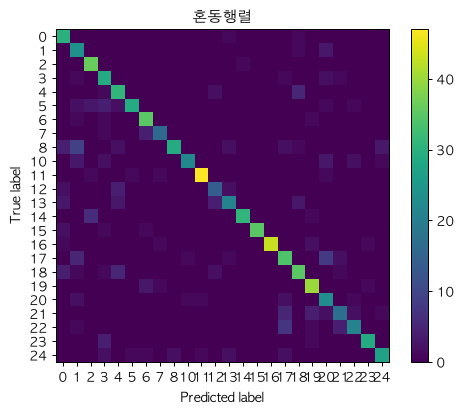

In [1]:
# 🤖 머신러닝 단계 — 그대로 실행해요
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split   # 학습용·시험용 나누기
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/sign_mnist_train_6000.csv', nrows=3000)   # 3,000장만
X = df.drop(columns=['label']) / 255    # 픽셀 밝기 0~1
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
model = KNeighborsClassifier(n_neighbors=3)   # 가장 닮은 그림 3장의 답을 따름
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('시험 정확도', round(accuracy_score(y_test, pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, include_values=False)
plt.title('혼동행렬'); plt.show()